In [649]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [650]:
class Processador_Imagem:
	def __init__(self):
		self.carregador = Carregador_Imagem() #todo
		self.segmentador = Segmentador() #todo
		self.detetor = DetetorObjetos()
		self.classificador = ClassificadorLego()
		self.resultados = Resultados()
	def processar(self, caminho):
		imagem = self.carregador.carregar_imagem(caminho)
		binaria = self.segmentador.binarizar_imagem(imagem)
		melhorada = self.segmentador.melhorar_imagem(binaria)
		return imagem, melhorada


1. Carregamento de imagens

In [651]:

class Carregador_Imagem:
	def carregar_imagem(self, caminho):#lê a imagem
		imagem = cv2.imread(caminho)
		if imagem is None:
			raise ValueError(f"Não foi possível carregar: {caminho}")
		return imagem
	def validar_imagem(self, imagem):#verifica se a imagem foi carregada corretamente
		pass

2. Análise, binarização e melhoramento

In [652]:
class Segmentador:
	def analisar_imagem(self, imagem):#estudar as caracteristicas da imagem
		cinza = cv2.cvtColor(imagem, cv2.COLOR_BGR2GRAY)
		hist = cv2.calcHist([cinza], [0], None, [256], [0, 256])
		nivel_fundo = np.argmax(hist)
		print("Nível de cinzento mais frequente:", nivel_fundo)
		plt.plot(hist)
		plt.title("Histograma (cinzento)")
		plt.show()
		return cinza
	def binarizar_imagem(self, imagem):#separar as peças do fundo
		cinzenta = cv2.cvtColor(imagem, cv2.COLOR_BGR2GRAY)
		_, binaria = cv2.threshold(cinzenta, 135, 255, cv2.THRESH_BINARY)
		return binaria
	def binarizar_imagem_inRange(self, imagem, limite_inferior, limite_superior):
		# Identificar o fundo através dos seus valores RGB
		fundo = cv2.inRange(imagem,np.array(limite_inferior),np.array(limite_superior))
		# Inverter a máscara para deixar as peças a branco
		binaria = cv2.bitwise_not(fundo)
		return binaria

	def melhorar_imagem(self, imagem_binaria):#reduzir o ruido e corrigir pequenas falhas
		elemento = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
		img = cv2.morphologyEx(imagem_binaria, cv2.MORPH_OPEN, elemento)
		img = cv2.morphologyEx(img, cv2.MORPH_CLOSE, elemento)
		return img

Foram encontradas 14 imagens.


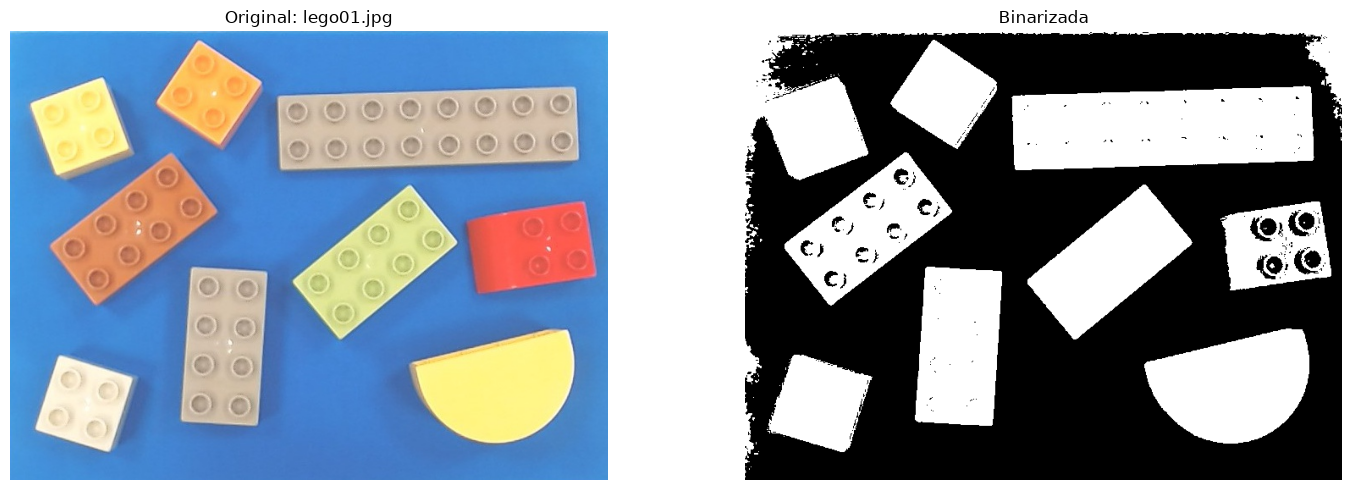

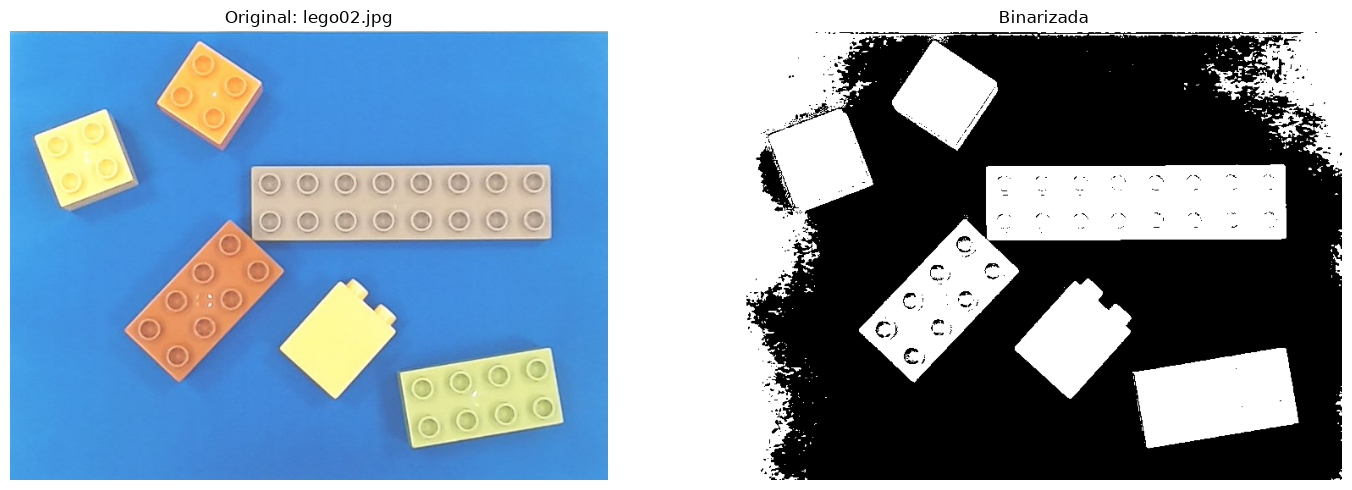

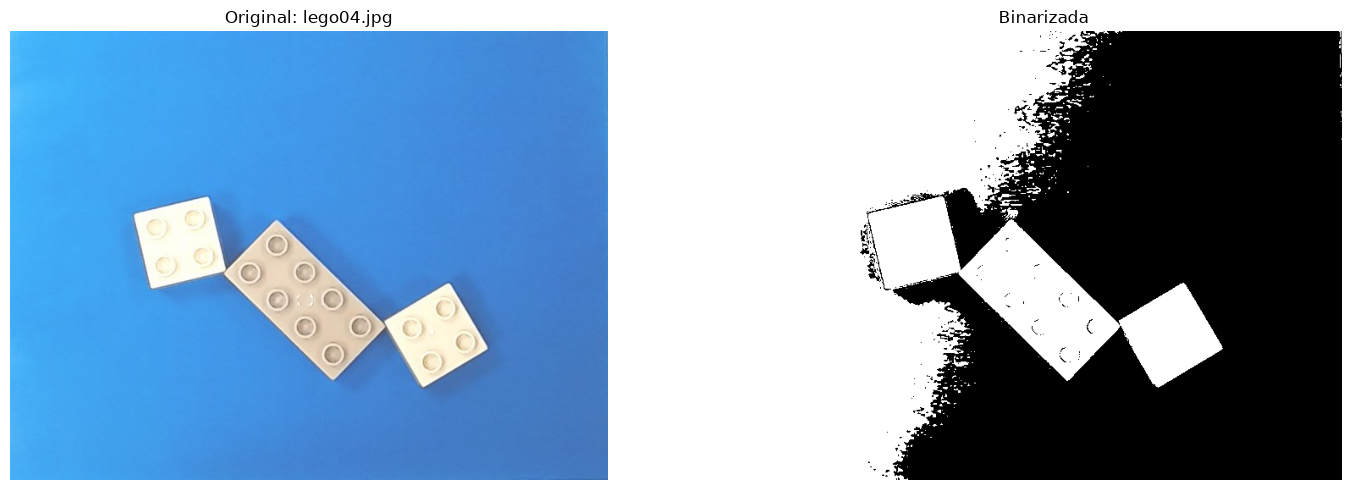

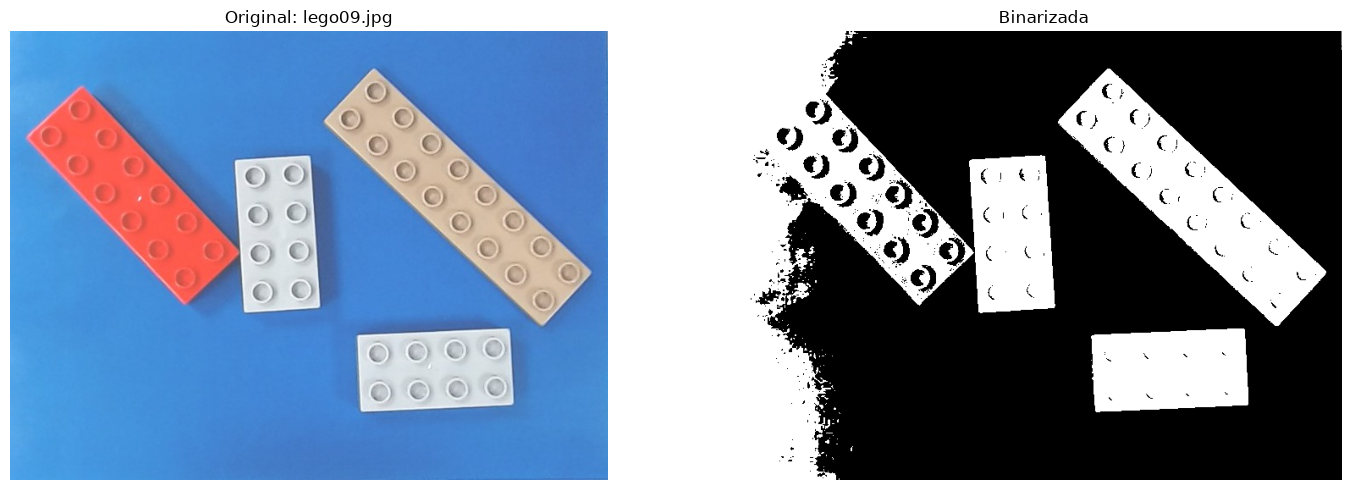

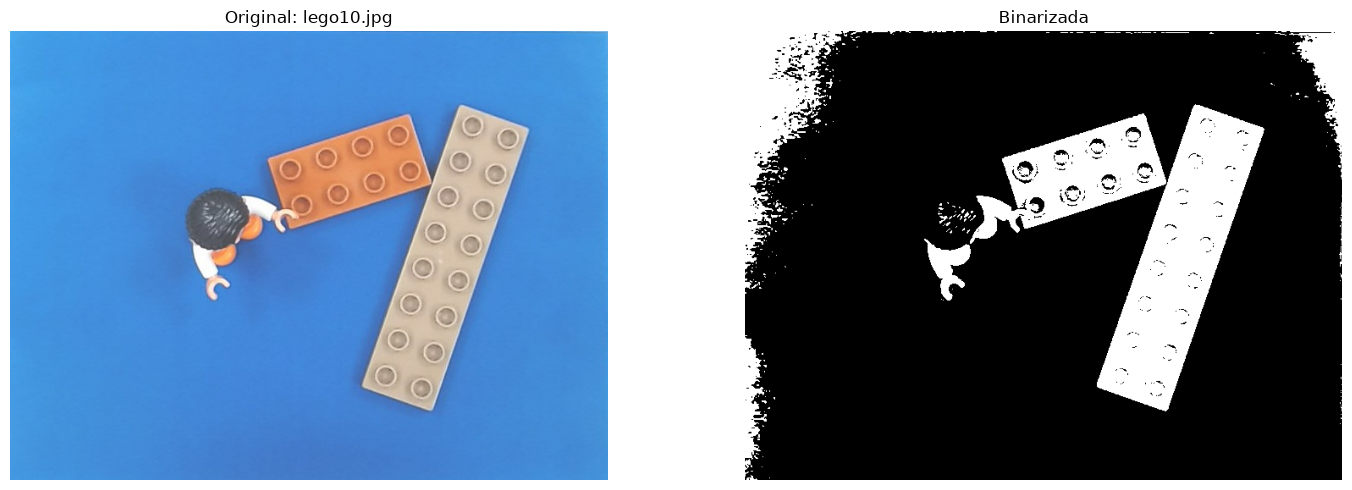

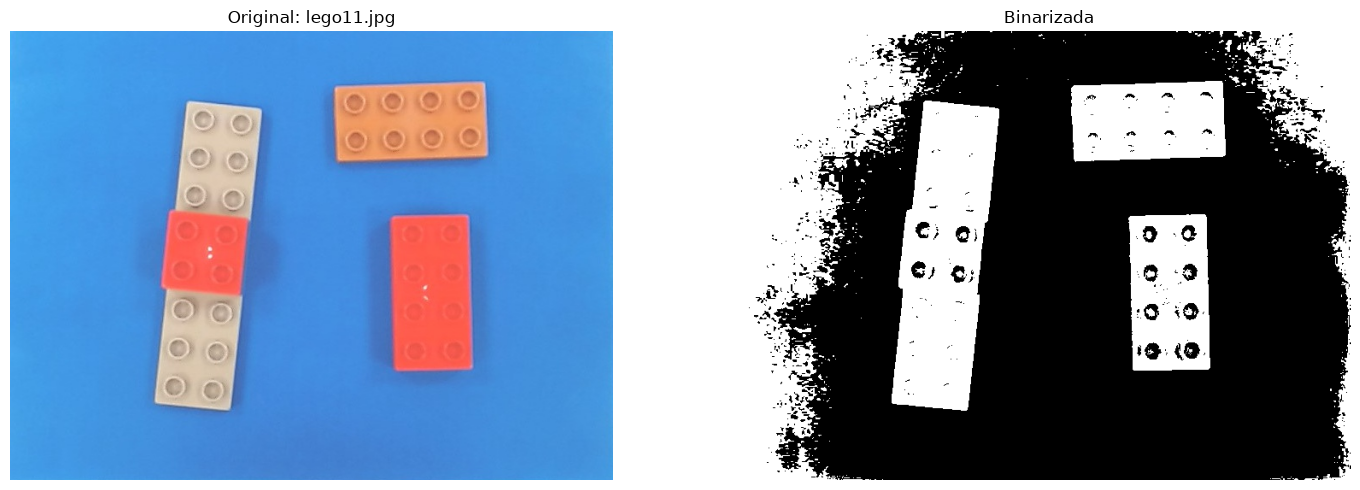

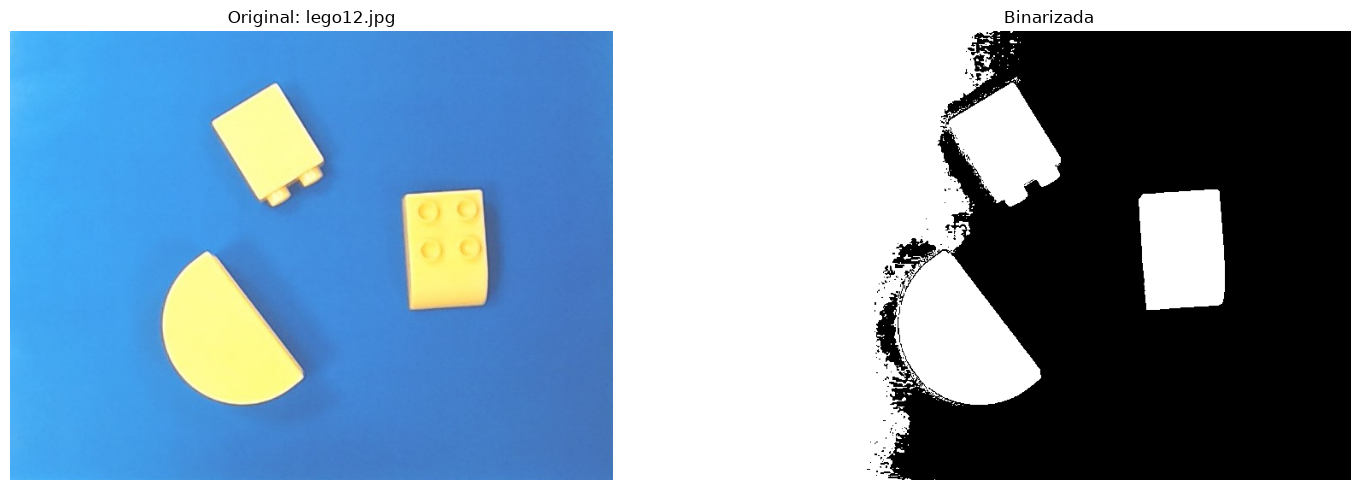

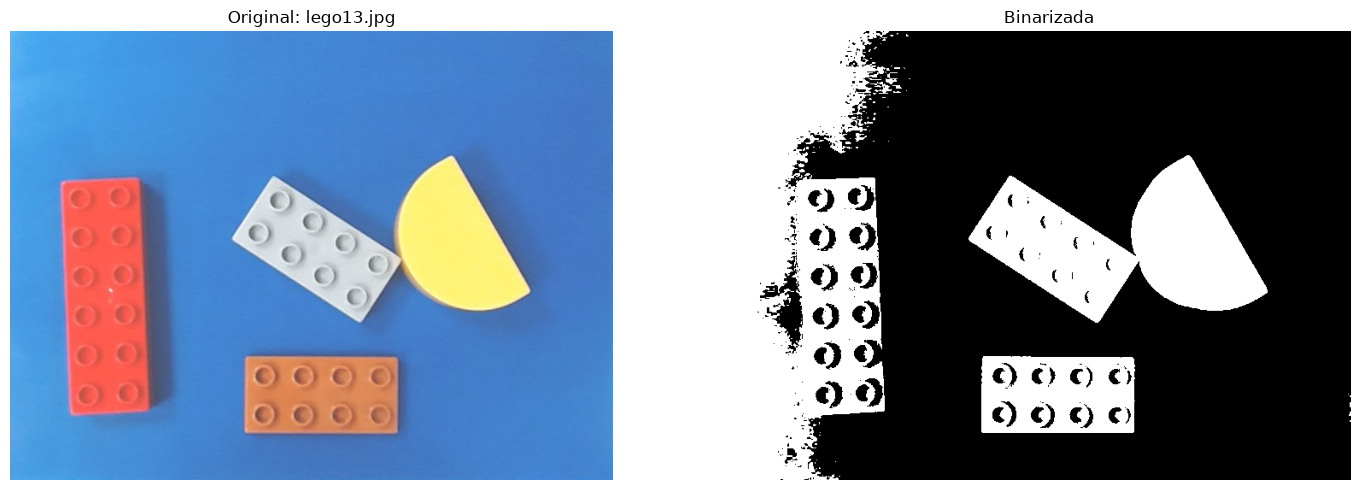

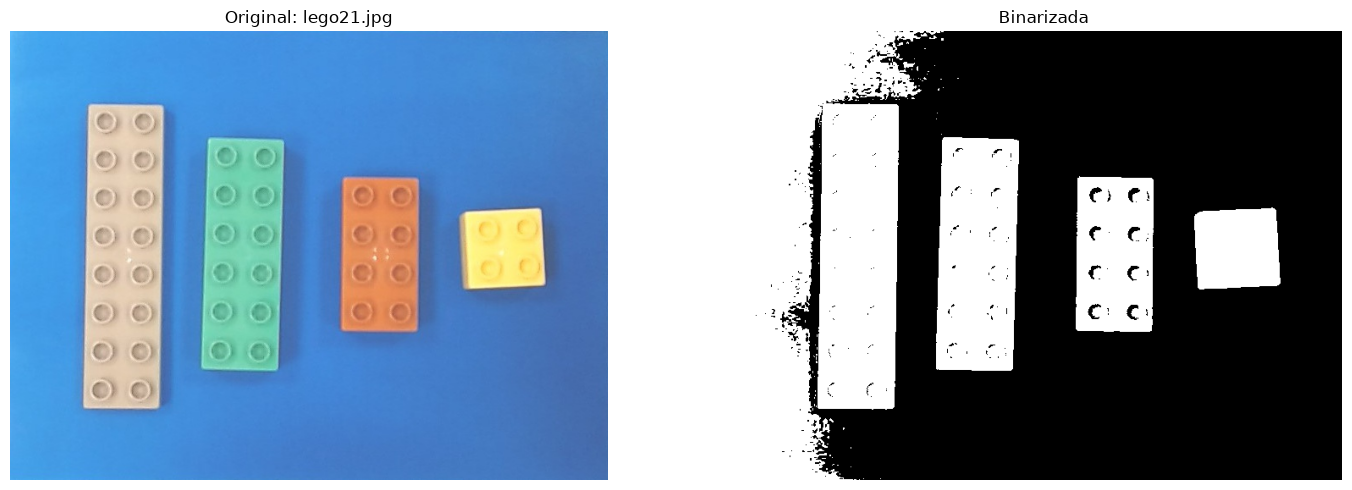

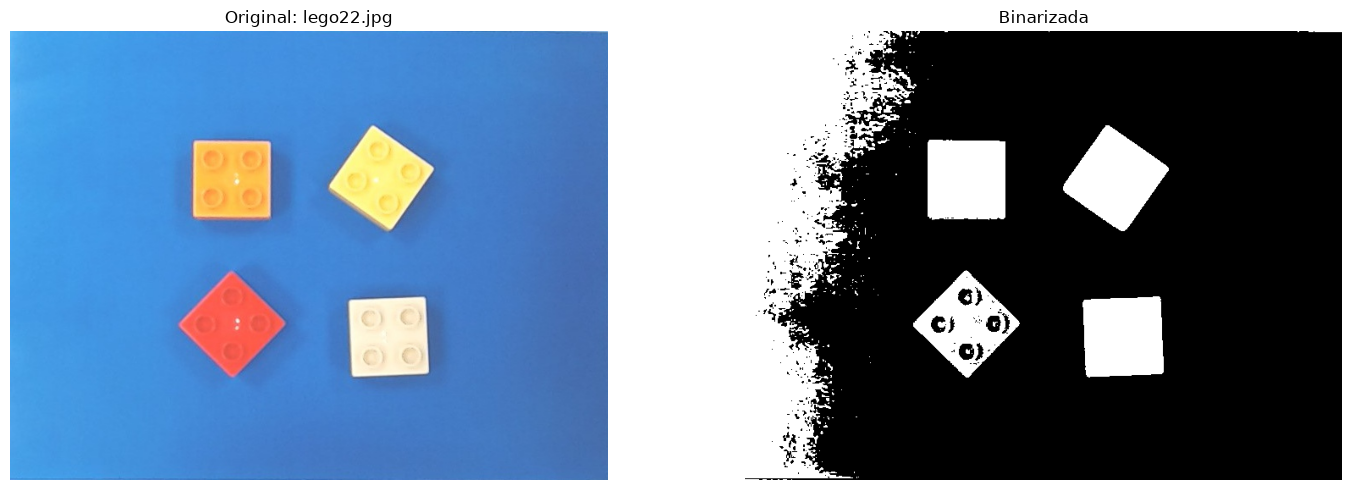

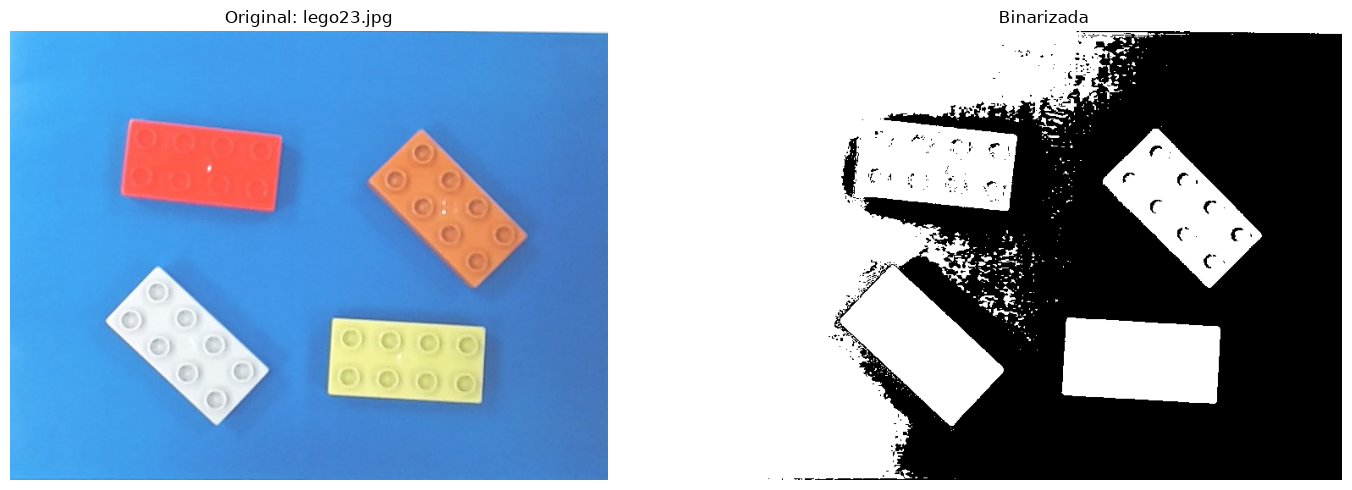

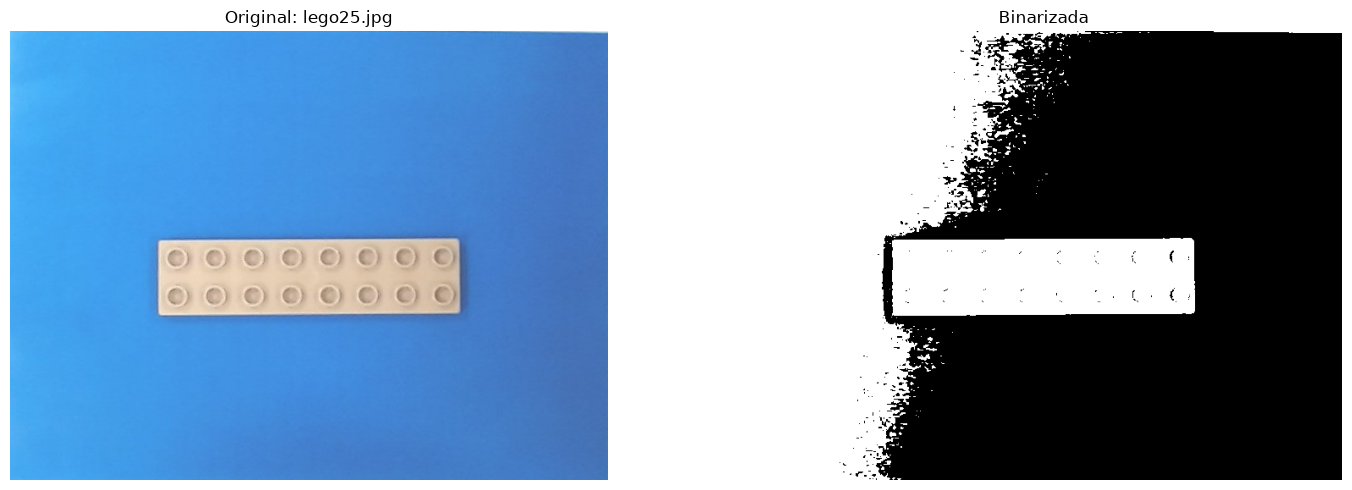

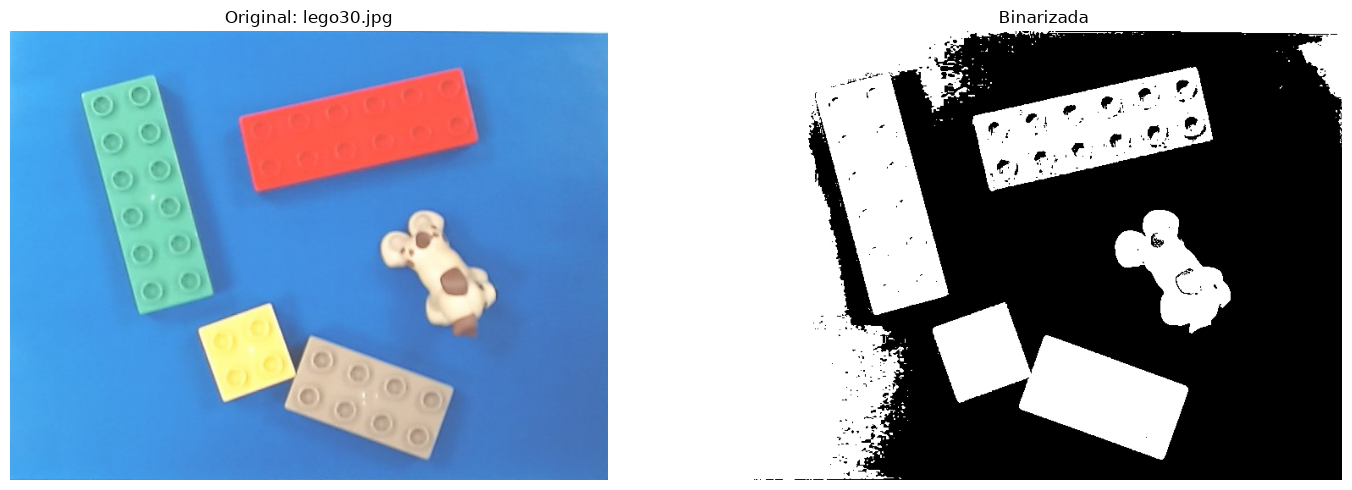

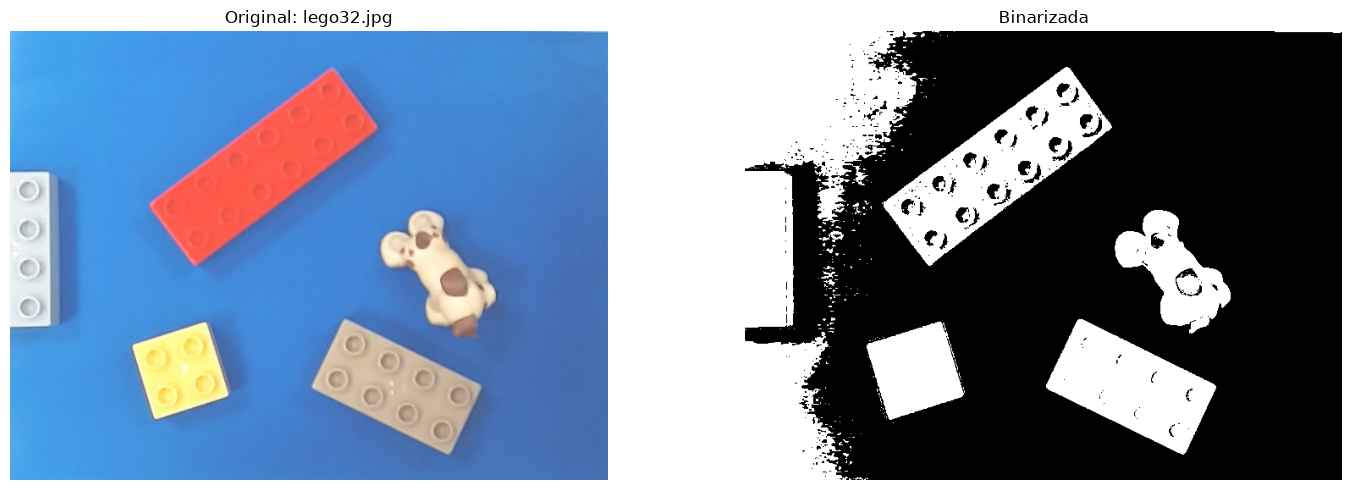

In [653]:

from pathlib import Path
import matplotlib.pyplot as plt
import cv2

# Pasta com todas as imagens de treino
pasta = Path("treino")

# Procurar todas as imagens
caminhos = sorted(list(pasta.glob("*.jpg")))

print(f"Foram encontradas {len(caminhos)} imagens.")

# Instanciar as classes
carregador = Carregador_Imagem()
segmentador = Segmentador()

# Processar todas as imagens
for caminho in caminhos:

    imagem_original = carregador.carregar_imagem(str(caminho))

    binaria = segmentador.binarizar_imagem(
        imagem_original
    )

    # Mostrar os três resultados
    fig, eixos = plt.subplots(1, 2, figsize=(15, 5))

    eixos[0].imshow(
        cv2.cvtColor(imagem_original, cv2.COLOR_BGR2RGB)
    )
    eixos[0].set_title(f"Original: {caminho.name}")

    eixos[1].imshow(binaria, cmap="gray")
    eixos[1].set_title("Binarizada")

    for eixo in eixos:
        eixo.axis("off")

    plt.tight_layout()
    plt.show()


3. Deteção e extração de caracteristicas

In [654]:
class DetetorObjetos:
	def detetar_objetos(self, imagem_binaria): #encontrar os contornos
		pass
	def extrair_caracteristicas(self, contorno): #calcular área, dimensões e outras propriedades
		pass
	def filtrar_objetos(self, objetos): #eliminar objetos irrelevantes
		pass


4. Identificação e classificação de peças lego

In [655]:
class ClassificadorLego:
	def distinguir_lego(self, caracterisiticas): #identificar peças potencialmente relevantes
		pass
	def classificar_peca(self, caracterisiticas): #classificar em 2x2, 2x4, 2x6 ou 2x8
		pass
	def classificar_objeto(self, objetos): #eliminar objetos irrelevates
		pass

In [656]:
class Resultados:
	def contar_pecas(self, objetos_classificados): #contar cada classe
		pass
	def desenhar_resultados(self, imagem, objetos_classificados): #desenhar contornos e etiquetas
		pass
	def apresentar_resultados(self, imagem, contagens): #mostrar os totais
		pass
	def avaliar_resultados(): #comparar previsoes com contagens corretas
		pass